In [ ]:
!gdown 1lr-s5EffXI29_fTP3OV7BAln2z1R6A0v
!file YouBike_traffic_2024.csv

Downloading...
From (original): https://drive.google.com/uc?id=1lr-s5EffXI29_fTP3OV7BAln2z1R6A0v
From (redirected): https://drive.google.com/uc?id=1lr-s5EffXI29_fTP3OV7BAln2z1R6A0v&confirm=t&uuid=da945cc0-8dba-4463-8222-588962997dfc
To: /content/YouBike_traffic_2024.csv
100% 713M/713M [00:12<00:00, 57.6MB/s]
YouBike_traffic_2024.csv: CSV Unicode text, UTF-8 (with BOM) text


In [ ]:
!gdown 1TJfyfcrxL3zq2oqxXqXFVITE5p2V8pAK
!file YouBike_traffic_2025.csv

Downloading...
From (original): https://drive.google.com/uc?id=1TJfyfcrxL3zq2oqxXqXFVITE5p2V8pAK
From (redirected): https://drive.google.com/uc?id=1TJfyfcrxL3zq2oqxXqXFVITE5p2V8pAK&confirm=t&uuid=abdc9b66-a2fa-490d-9bf6-13813e14c9f2
To: /content/YouBike_traffic_2025.csv
100% 993M/993M [00:18<00:00, 54.2MB/s]
YouBike_traffic_2025.csv: CSV Unicode text, UTF-8 (with BOM) text


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
df_youbike_2024 = pd.read_csv('YouBike_traffic_2024.csv')
df_youbike_2024.info()

/tmp/ipykernel_3138/632304525.py:1: DtypeWarning: Columns (5) have mixed types. Specify dtype option on import or set low_memory=False.
  df_youbike_2024 = pd.read_csv('YouBike_traffic_2024.csv')


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6291342 entries, 0 to 6291341
Data columns (total 7 columns):
 #   Column          Dtype 
---  ------          ----- 
 0   rent_time       object
 1   rent_station    object
 2   return_time     object
 3   return_station  object
 4   rent            object
 5   bike_type       object
 6   infodate        object
dtypes: object(7)
memory usage: 336.0+ MB


In [ ]:
df_youbike_2024

,rent_time,rent_station,return_time,return_station,rent,bike_type,infodate
0,2024-01-22 08:00:00,新生和平路口東北側,2024-01-22 09:00:00,新生南路三段66號前,00:07:02,NaN,2024-01-22
1,2024-01-22 12:00:00,臺大小福樓東側,2024-01-22 12:00:00,捷運臺電大樓站(5號出口),00:12:21,NaN,2024-01-22
2,2024-01-22 21:00:00,捷運公館站(2號出口),2024-01-22 22:00:00,臺灣科技大學側門,00:19:06,NaN,2024-01-22
3,2024-01-22 23:00:00,捷運公館站(2號出口),2024-01-23 00:00:00,臺灣科技大學側門,00:26:58,NaN,2024-01-22
4,2024-01-22 18:00:00,臺大工綜館南側,2024-01-22 18:00:00,臺大椰林小舖,00:04:00,NaN,2024-01-22
...,...,...,...,...,...,...,...
6291337,2024-12-05 18:00:00,新生南路三段82號前,2024-12-05 18:00:00,臺大社會系館南側,00:06:02,一般車,2024-12-05
6291338,2024-12-05 20:00:00,辛亥復興路口西北側,2024-12-05 22:00:00,羅斯福路三段311號前,01:29:12,一般車,2024-12-05
6291339,2024-12-05 16:00:00,捷運公館站(2號出口),2024-12-05 17:00:00,捷運公館站(2號出口),00:56:22,一般車,2024-12-05
6291340,2024-12-05 19:00:00,捷運公館站(2號出口),2024-12-05 20:00:00,捷運台北101/世貿站(2號出口),00:39:28,一般車,2024-12-05


In [ ]:
file_url = 'https://tcgbusfs.blob.core.windows.net/dotapp/youbike/v2/youbike_immediate.json'
stationInfo = pd.read_json(file_url)
stationInfo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1824 entries, 0 to 1823
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   sno                     1824 non-null   int64  
 1   sna                     1824 non-null   object 
 2   sarea                   1824 non-null   object 
 3   mday                    1824 non-null   object 
 4   ar                      1824 non-null   object 
 5   sareaen                 1824 non-null   object 
 6   snaen                   1824 non-null   object 
 7   aren                    1824 non-null   object 
 8   act                     1824 non-null   int64  
 9   srcUpdateTime           1824 non-null   object 
 10  updateTime              1824 non-null   object 
 11  infoTime                1824 non-null   object 
 12  infoDate                1824 non-null   object 
 13  Quantity                1824 non-null   int64  
 14  available_rent_bikes    1824 non-null   

In [ ]:
stationInfo[stationInfo['sarea'] == '臺大公館校區']

,sno,sna,sarea,mday,ar,sareaen,snaen,aren,act,srcUpdateTime,updateTime,infoTime,infoDate,Quantity,available_rent_bikes,latitude,longitude,available_return_bikes
1759,500119005,YouBike2.0_臺大水源舍區A棟,臺大公館校區,2026-11-07 20:35:03,汀洲路三段60巷2弄路側(A舍北側),NTU Dist,YouBike2.0_NTU ShuiYuan Dorms(A),Aly. 2， Ln. 60， Sec. 3， Tingzhou Rd. Dorms A(N...,1,2026-11-07 20:35:52,2026-11-07 20:35:52,2026-11-07 20:35:03,2026-11-07,37,21,25.01493,121.53044,16
1760,500119006,YouBike2.0_臺大卓越研究大樓,臺大公館校區,2026-11-07 20:35:03,臺大水源舍區C南側,NTU Dist,YouBike2.0_NTU Complex for Research Excellence,NTU Prince House Chang Hsing Dorms C(South),1,2026-11-07 20:35:52,2026-11-07 20:35:52,2026-11-07 20:35:03,2026-11-07,92,2,25.01466,121.52917,90
1761,500119007,YouBike2.0_臺大水源修齊會館,臺大公館校區,2026-11-07 20:35:03,思源街16號之1旁,NTU Dist,YouBike2.0_NTU ShuiYuan HsiuChi House,No.16-1， Siyuan St.,1,2026-11-07 20:35:52,2026-11-07 20:35:52,2026-11-07 20:35:03,2026-11-07,35,10,25.01411,121.52997,23
1762,500119008,YouBike2.0_臺大檔案展示館,臺大公館校區,2026-11-07 20:35:03,臺大檔案展示館東北側,NTU Dist,YouBike2.0_NTU Archives,NTU Archives(Northeast),1,2026-11-07 20:35:52,2026-11-07 20:35:52,2026-11-07 20:35:03,2026-11-07,10,0,25.01391,121.52895,9
1763,500119009,YouBike2.0_臺大水源舍區B棟,臺大公館校區,2026-11-07 20:35:03,汀洲路三段60巷2弄路側(B舍北側),NTU Dist,YouBike2.0_NTU ShuiYuan Dorms(B),Aly. 2， Ln. 60， Sec. 3， Tingzhou Rd. Dorms B(N...,1,2026-11-07 20:35:52,2026-11-07 20:35:52,2026-11-07 20:35:03,2026-11-07,30,12,25.01525,121.53009,17
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1819,500119099,YouBike2.0_臺大博理館北側,臺大公館校區,2026-11-07 20:35:04,臺大博理館北側,NTU Dist,YouBike2.0_NTU Barry Lam Hall(North),NTU Barry Lam Hall(North),1,2026-11-07 20:35:52,2026-11-07 20:35:52,2026-11-07 20:35:04,2026-11-07,36,2,25.01945,121.54245,34
1820,500119100,YouBike2.0_臺大博理館東側,臺大公館校區,2026-11-07 20:35:04,臺大博理館東側,NTU Dist,YouBike2.0_NTU Barry Lam Hall(East),NTU Barry Lam Hall(North),1,2026-11-07 20:35:52,2026-11-07 20:35:52,2026-11-07 20:35:04,2026-11-07,24,0,25.01929,121.54264,24
1821,500119101,YouBike2.0_臺大德田館東北側,臺大公館校區,2026-11-07 20:35:04,臺大德田館東北側,NTU Dist,YouBike2.0_NTU Der Tian Hall (Northeast),NTU Der Tian Hall (Northeast),1,2026-11-07 20:35:52,2026-11-07 20:35:52,2026-11-07 20:35:04,2026-11-07,56,2,25.01976,121.54197,54
1822,500119102,YouBike2.0_臺大普通教學館東側,臺大公館校區,2026-11-07 20:35:04,臺大普通教學館東側,NTU Dist,YouBike2.0_NTU Putong Lecture Building (East),NTU Putong Lecture Building (East),1,2026-11-07 20:35:52,2026-11-07 20:35:52,2026-11-07 20:35:04,2026-11-07,42,2,25.01861,121.53717,40


# NTU Campus Area YouBike Analysis
**Study area** = every station with `sarea == '臺大公館校區'` **plus** the stations listed in `可能缺漏站點清單.csv`
(長興街 dorms, 溫州街, 羅斯福路三段, 辛亥路, 復興南路二段, 科技大樓/國北教大 …; the list is built into the next cells and can be overridden by uploading your own CSV).
All trips that **start or end** at a study-area station are analysed.

Station names are matched with a normalised key (no `YouBike2.0_` prefix, 台→臺, full-width brackets → half-width, no spaces), so trip-CSV names and API names line up.


In [ ]:
# Setup: Chinese font + map / routing libraries (Colab)
!pip -q install osmnx
!apt-get -qq install -y fonts-noto-cjk > /dev/null

import os, io, math, time
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib import font_manager
from matplotlib.lines import Line2D
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.cm import ScalarMappable
from concurrent.futures import ThreadPoolExecutor
from PIL import Image, ImageDraw, ImageEnhance
from IPython.display import display, Markdown

for f in ['/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc']:
    if os.path.exists(f):
        font_manager.fontManager.addfont(f)
        plt.rcParams['font.family'] = font_manager.FontProperties(fname=f).get_name()
plt.rcParams['axes.unicode_minus'] = False

# Colors
BLUE, ORANGE = '#2a78d6', '#eb6834'
GREEN, RED = '#0ca30c', '#d03b3b'
INK, INK2 = '#0b0b0b', '#52514e'

# Every figure / table saved below is recorded here and uploaded to Google Drive in the last section
OUT_FILES = []
def saved(path):
    if path not in OUT_FILES:
        OUT_FILES.append(path)
    return path

In [ ]:
# --- Study-area stations ---
# 1) every station whose sarea is 臺大公館校區, plus
# 2) the extra stations listed in 可能缺漏站點清單.csv (長興街 dorms, 溫州街, 復興南路, 辛亥路, 科技大樓 ...)
EXTRA_CSV = '可能缺漏站點清單.csv'
EXTRA_CSV_TEXT = """站點名稱,現有區域,在你的列表,理由
臺大水源舍區A棟,臺大公館校區,是,水源校區（思源街），檔案已含自來水園區一帶
臺大水源舍區B棟,臺大公館校區,是,同上
臺大水源舍區C棟,臺大公館校區,是,同上
臺大水源修齊會館,臺大公館校區,是,同上
臺大卓越研究大樓,臺大公館校區,是,校內站
臺大檔案展示館,臺大公館校區,是,校內站
臺大人文館,臺大公館校區,是,校內站
臺大男七舍前,大安區,是,長興街宿舍區，男六舍、男八舍已在檔案中
臺大環研大樓,大安區,是,校內站，近長興街
臺大土木研究大樓前,大安區,是,校內站
臺大醫學院附設癌醫中心,大安區,是,基隆路東側，可能略超出檔案東界
復興南路二段280號前,大安區,是,對街的273號前已在檔案中
復興南路二段340巷口,大安區,,介於273號前與辛亥復興路口之間
辛亥新生路口西北側,大安區,是,同路口的東南側已在檔案中
捷運科技大樓站(台北教育大學),大安區,是,檔案已含捷運科技大樓站
和平東路二段90巷,大安區,是,檔案已含和平東路二段76巷
國立臺北教育大學創意館,大安區,,檔案已含國北教大實小東側門
溫州公園,大安區,,溫州街一帶（使用者指定補入）
辛亥泰順街口,大安區,,溫州街一帶（使用者指定補入）
辛亥路一段30號前,大安區,,溫州街一帶（使用者指定補入）
羅斯福路三段245號前,大安區,,溫州街一帶（使用者指定補入）
羅斯福路三段283巷,大安區,,溫州街一帶（使用者指定補入）
羅斯福路三段311號前,大安區,,溫州街一帶（使用者指定補入）"""
if not os.path.exists(EXTRA_CSV):      # upload your own copy to Colab to override this built-in list
    with open(EXTRA_CSV, 'w', encoding='utf-8-sig') as f:
        f.write(EXTRA_CSV_TEXT)
extra_list = pd.read_csv(EXTRA_CSV, encoding='utf-8-sig').fillna('')

def norm_name(s):
    """Matching key for station names: drop the YouBike prefix, unify 台/臺, full-width brackets and spaces."""
    s = str(s)
    for p in ('YouBike2.0_', 'YouBike1.0_'):
        s = s.replace(p, '')
    s = s.replace('台', '臺').replace('（', '(').replace('）', ')')
    return ''.join(s.split())

stations_all = stationInfo.copy()
stations_all['name'] = stations_all['sna'].map(norm_name)
stations_all['name_en'] = (stations_all['snaen'].astype(str)
                           .str.replace('YouBike2.0_', '', regex=False).str.strip())

core = stations_all[stations_all['sarea'] == '臺大公館校區']
extra_rows, unmatched = [], []
for raw in extra_list['站點名稱']:
    key = norm_name(raw)
    hit = stations_all[stations_all['name'] == key]
    if hit.empty:                       # fall back to a substring match (slightly different suffix)
        hit = stations_all[stations_all['name'].str.contains(key, regex=False)]
    if hit.empty:
        unmatched.append(raw)
    else:
        extra_rows.append(hit.iloc[[0]])
extra = pd.concat(extra_rows) if extra_rows else stations_all.iloc[0:0]

ntu = (pd.concat([core.assign(group='臺大公館校區'), extra.assign(group='周邊補入站')])
       .drop_duplicates('sno', keep='first').reset_index(drop=True))
ntu_names = set(ntu['name'])
n_added = int((ntu['group'] == '周邊補入站').sum())
print(f'{len(core)} stations in sarea 臺大公館校區 + {n_added} added from {EXTRA_CSV} '
      f'({len(extra_list)} listed, {len(extra_list) - len(unmatched) - n_added} of them already in 臺大公館校區)')
print(f'=> {len(ntu)} study-area stations, total capacity {ntu["Quantity"].sum():,} docks')
if unmatched:
    print('Not found in the live station API (check spelling):', unmatched)
display(ntu.loc[ntu['group'] == '周邊補入站', ['name', 'sarea', 'Quantity', 'latitude', 'longitude']]
        .reset_index(drop=True))

65 stations in sarea 臺大公館校區 + 16 added from 可能缺漏站點清單.csv (23 listed, 7 of them already in 臺大公館校區)
=> 81 study-area stations, total capacity 2,862 docks


,name,sarea,Quantity,latitude,longitude
0,臺大男七舍前,大安區,20,25.01537,121.54698
1,臺大環研大樓,大安區,41,25.01234,121.54503
2,臺大土木研究大樓前,大安區,24,25.01787,121.54760
3,臺大醫學院附設癌醫中心,大安區,20,25.01426,121.54382
4,復興南路二段280號前,大安區,27,25.02429,121.54328
5,復興南路二段340巷口,大安區,11,25.02253,121.54326
6,辛亥新生路口西北側,大安區,41,25.02267,121.53410
7,捷運科技大樓站(臺北教育大學),大安區,54,25.02472,121.54417
8,和平東路二段90巷,大安區,20,25.02468,121.53965
9,國立臺北教育大學創意館,大安區,32,25.02305,121.54394


In [ ]:
# Load trips that touch a study-area station (read in chunks to keep memory low)
# Station names are normalised with norm_name() so they match the API names (台/臺, brackets, spaces)
_norm_cache = {}
def norm_col(s):
    new = [x for x in s.dropna().unique() if x not in _norm_cache]
    _norm_cache.update({x: norm_name(x) for x in new})
    return s.map(_norm_cache)

def load_ntu_trips(path):
    cols = ['rent_time', 'rent_station', 'return_time', 'return_station', 'rent']
    parts = []
    for chunk in pd.read_csv(path, usecols=cols, dtype=str, chunksize=1_000_000):
        chunk['rent_station'] = norm_col(chunk['rent_station'])
        chunk['return_station'] = norm_col(chunk['return_station'])
        keep = chunk['rent_station'].isin(ntu_names) | chunk['return_station'].isin(ntu_names)
        parts.append(chunk[keep])
    return pd.concat(parts, ignore_index=True)

files = [f for f in ['YouBike_traffic_2024.csv', 'YouBike_traffic_2025.csv'] if os.path.exists(f)]
trips = pd.concat([load_ntu_trips(f) for f in files], ignore_index=True)

# Parse times and trip duration ('rent' column, e.g. '00:07:02')
trips['rent_time'] = pd.to_datetime(trips['rent_time'], errors='coerce')
trips['return_time'] = pd.to_datetime(trips['return_time'], errors='coerce')
trips['duration_s'] = pd.to_timedelta(trips['rent'], errors='coerce').dt.total_seconds()
trips = trips.dropna(subset=['rent_time', 'return_time', 'duration_s'])
# Basic sanity: drop non-positive durations and trips longer than a day
trips = trips[(trips['duration_s'] > 0) & (trips['duration_s'] <= 24 * 3600)]
trips = trips[trips['return_time'] >= trips['rent_time']].reset_index(drop=True)

trips['rent_hour'] = trips['rent_time'].dt.hour
trips['return_hour'] = trips['return_time'].dt.hour
trips['rent_at_ntu'] = trips['rent_station'].isin(ntu_names)
trips['return_at_ntu'] = trips['return_station'].isin(ntu_names)

n_days = trips['rent_time'].dt.normalize().nunique()   # days with data, used for daily averages
print(f'Files: {files}')
print(f'{len(trips):,} trips touching study-area stations over {n_days} days '
      f'({trips["rent_time"].min():%Y-%m-%d} to {trips["rent_time"].max():%Y-%m-%d})')

# Match check: NTU stations never seen in the trip data (e.g. renamed or newly opened)
seen = set(trips['rent_station']) | set(trips['return_station'])
missing = sorted(ntu_names - seen)
print(f'{len(ntu_names) - len(missing)}/{len(ntu_names)} study-area stations found in trip data')
if missing:
    print('Not found:', missing)

Files: ['YouBike_traffic_2024.csv', 'YouBike_traffic_2025.csv']
9,663,924 trips touching study-area stations over 729 days (2024-01-01 to 2025-12-31)
75/81 study-area stations found in trip data
Not found: ['臺大博理館北側', '臺大博理館東側', '臺大德田館東北側', '臺大數學研究中心(東側)', '臺大普通教學館東側', '臺大次震宇宙館西側']


## 1. Geographic Station Capacity Map
**Basemap:** OpenStreetMap's bicycle layer ([CyclOSM](https://www.cyclosm.org/)): cycle lanes, bike paths and bike parking are drawn on the map. Set `THUNDERFOREST_KEY` to switch to the *Cycle Map* (OpenCycleMap) layer of openstreetmap.org instead.

**Range and resolution** are controlled in the next cell: `MAP_BOUNDS` (or the margins `LON_PAD`, `LAT_PAD` — longitude is padded more for a wide map), `ZOOM` (17 ≈ 1.1 m per pixel) and `MAP_DPI`.
Every map is saved at **native resolution (1 map pixel = 1 image pixel)**, several thousand pixels wide, so it can be pasted large into the report; the notebook only shows a smaller preview. Panels of the 3-hour figures are stacked vertically.

Circle area is proportional to the value shown. Blue = 臺大公館校區 stations, orange = added nearby stations.


In [ ]:
# --- Basemap: OpenStreetMap bicycle layer. Map range and resolution are all set here. ---
# Layer: CyclOSM = the bicycle layer of OpenStreetMap (cycle lanes, bike paths, bike parking). Free, no key.
# To use the "Cycle Map" layer of openstreetmap.org instead (Thunderforest OpenCycleMap, 512-px retina tiles),
# paste a free API key from https://manage.thunderforest.com into THUNDERFOREST_KEY.
THUNDERFOREST_KEY = ''
if THUNDERFOREST_KEY:
    LAYER, TILE, SUBDOMAINS = 'opencyclemap', 512, 'a'
    TILE_URL = 'https://tile.thunderforest.com/cycle/{z}/{x}/{y}@2x.png?apikey=' + THUNDERFOREST_KEY
    ATTRIBUTION = 'Maps © Thunderforest · Data © OpenStreetMap contributors'
else:
    LAYER, TILE, SUBDOMAINS = 'cyclosm', 256, 'abc'
    TILE_URL = 'https://{s}.tile-cyclosm.openstreetmap.fr/cyclosm/{z}/{x}/{y}.png'
    ATTRIBUTION = '© OpenStreetMap contributors · CyclOSM'
HEADERS = {'User-Agent': 'NTU-YouBike-analysis/1.0 (student data-visualization notebook)'}

# Range in degrees. None = fit every study-area station, then add the margins below.
MAP_BOUNDS = None                  # or set it, e.g. (121.512, 25.006, 121.562, 25.034) = (lon_min, lat_min, lon_max, lat_max)
LON_PAD, LAT_PAD = 0.008, 0.003    # margin; wider in longitude -> a landscape map for the report

# Resolution
ZOOM = 17          # tile zoom: 16 ≈ 2.2 m/px, 17 ≈ 1.1 m/px, 18 ≈ 0.54 m/px (256-px tiles at Taipei's latitude)
MAP_DPI = 200      # figures are saved so 1 map pixel = 1 output pixel; DPI only sets the text/line scale
PREVIEW_W = 1800   # width of the preview shown in the notebook (the saved PNGs keep full size)

S = 2 ** (ZOOM - 16) * TILE / 256     # size factor vs. the zoom-16 maps (circles, text, lines keep their ground size)

def lon_to_x(lon):                    # global pixel coordinates at ZOOM
    return (np.asarray(lon, dtype=float) + 180.0) / 360.0 * 2 ** ZOOM * TILE

def lat_to_y(lat):
    r = np.radians(np.asarray(lat, dtype=float))
    return (1 - np.log(np.tan(r) + 1 / np.cos(r)) / np.pi) / 2 * 2 ** ZOOM * TILE

if MAP_BOUNDS is None:
    MAP_BOUNDS = (ntu['longitude'].min() - LON_PAD, ntu['latitude'].min() - LAT_PAD,
                  ntu['longitude'].max() + LON_PAD, ntu['latitude'].max() + LAT_PAD)
LON_MIN, LAT_MIN, LON_MAX, LAT_MAX = MAP_BOUNDS
X0, Y0 = float(lon_to_x(LON_MIN)), float(lat_to_y(LAT_MAX))
MAP_W = int(round(float(lon_to_x(LON_MAX)) - X0))
MAP_H = int(round(float(lat_to_y(LAT_MIN)) - Y0))

def to_px(lon, lat):
    return lon_to_x(lon) - X0, lat_to_y(lat) - Y0

# --- Tile download (cached on disk, 4 parallel requests, retries) ---
TILE_CACHE = f'tiles/{LAYER}/{ZOOM}'

def fetch_tile(x, y):
    path = f'{TILE_CACHE}/{x}_{y}.png'
    if not os.path.exists(path):
        url = TILE_URL.format(s=SUBDOMAINS[(x + y) % len(SUBDOMAINS)], z=ZOOM, x=x, y=y)
        for attempt in range(5):
            try:
                r = requests.get(url, headers=HEADERS, timeout=30)
                if r.status_code == 200 and r.headers.get('content-type', '').startswith('image'):
                    with open(path, 'wb') as fh:
                        fh.write(r.content)
                    break
            except requests.RequestException:
                pass
            time.sleep(2 * (attempt + 1))
        else:
            return None
    return Image.open(path).convert('RGB')

def render_basemap():
    os.makedirs(TILE_CACHE, exist_ok=True)
    tx0, ty0 = int(X0 // TILE), int(Y0 // TILE)
    tx1, ty1 = int((X0 + MAP_W - 1) // TILE), int((Y0 + MAP_H - 1) // TILE)
    jobs = [(x, y) for y in range(ty0, ty1 + 1) for x in range(tx0, tx1 + 1)]
    print(f'Fetching {len(jobs)} {LAYER} tiles (cached in {TILE_CACHE}/) ...')
    with ThreadPoolExecutor(max_workers=4) as ex:
        tiles = list(ex.map(lambda xy: fetch_tile(*xy), jobs))
    canvas = Image.new('RGB', ((tx1 - tx0 + 1) * TILE, (ty1 - ty0 + 1) * TILE), (235, 235, 235))
    for (x, y), t in zip(jobs, tiles):
        if t is not None:
            canvas.paste(t if t.size == (TILE, TILE) else t.resize((TILE, TILE)),
                         ((x - tx0) * TILE, (y - ty0) * TILE))
    n_bad = sum(t is None for t in tiles)
    if n_bad:
        print(f'WARNING: {n_bad} tiles could not be downloaded (shown grey). Re-run this cell to retry.')
    ox0, oy0 = int(round(X0 - tx0 * TILE)), int(round(Y0 - ty0 * TILE))
    return canvas.crop((ox0, oy0, ox0 + MAP_W, oy0 + MAP_H)).convert('RGBA')

BASEMAP = render_basemap()
m_per_px = 40075016.7 * math.cos(math.radians((LAT_MIN + LAT_MAX) / 2)) / (2 ** ZOOM * TILE)
print(f'Basemap {MAP_W} x {MAP_H} px, {LAYER} zoom {ZOOM} (≈{m_per_px:.2f} m/px), '
      f'lon {LON_MIN:.4f}–{LON_MAX:.4f}, lat {LAT_MIN:.4f}–{LAT_MAX:.4f}')

# --- Drawing helpers ---
def px2pt(px):                         # image pixels -> matplotlib points (figures are saved 1:1)
    return np.asarray(px) * 72.0 / MAP_DPI

def radius(v, vmax, rmax=30 * S, rmin=3 * S):
    # Area-proportional radius in pixels
    return rmin + (rmax - rmin) * np.sqrt(abs(v) / vmax) if vmax > 0 else rmin

def hex_rgba(h, alpha):
    h = h.lstrip('#'); return tuple(int(h[i:i + 2], 16) for i in (0, 2, 4)) + (int(alpha * 255),)

def dot(color, label, alpha=1.0):      # legend marker
    return Line2D([], [], marker='o', ls='', ms=float(px2pt(18 * S)), mfc=color, mec='white',
                  alpha=alpha, label=label)

def draw_circles(df, value_col, vmax, color_fn, alpha=0.65):
    """One circle per station on a copy of the basemap; color_fn(row) -> hex. Biggest first so small ones stay visible."""
    img = BASEMAP.copy()
    layer = Image.new('RGBA', img.size, (0, 0, 0, 0))
    d = ImageDraw.Draw(layer)
    for _, r in df.reindex(df[value_col].abs().sort_values(ascending=False).index).iterrows():
        if r[value_col] == 0:
            continue
        x, y = to_px(r['longitude'], r['latitude']); rad = radius(r[value_col], vmax)
        d.ellipse([x - rad, y - rad, x + rad, y + rad], fill=hex_rgba(color_fn(r), alpha),
                  outline=(255, 255, 255, 235), width=max(1, int(round(2 * S))))
    return Image.alpha_composite(img, layer)

def map_figure(n_panels=1, title_px=44, header_px=80, footer_px=0):
    """Figure whose map panels are drawn at native pixel size, stacked vertically (wide maps)."""
    t, hd, ft = title_px * S, header_px * S, footer_px * S
    fig_h = hd + n_panels * (t + MAP_H) + ft
    fig = plt.figure(figsize=(MAP_W / MAP_DPI, fig_h / MAP_DPI), dpi=MAP_DPI)
    fig.patch.set_facecolor('white')
    axes = []
    for i in range(n_panels):
        top = hd + i * (t + MAP_H) + t
        axes.append(fig.add_axes([0, 1 - (top + MAP_H) / fig_h, 1, MAP_H / fig_h]))
    return fig, axes

def add_header(fig, text, legend=None, header_px=80):
    yc = 1 - (header_px * S / 2) / (fig.get_figheight() * MAP_DPI)
    fig.text(0.006, yc, text, ha='left', va='center', fontsize=float(px2pt(26 * S)), color=INK)
    if legend:
        fig.legend(handles=legend, loc='center right', bbox_to_anchor=(0.994, yc), frameon=False,
                   fontsize=float(px2pt(16 * S)), ncol=len(legend), handletextpad=0.3, columnspacing=1.5)

def attribution(ax):
    ax.text(MAP_W - 6 * S, MAP_H - 6 * S, ATTRIBUTION, ha='right', va='bottom',
            fontsize=float(px2pt(11 * S)), color=INK2,
            bbox=dict(fc=(1, 1, 1, 0.75), ec='none', pad=float(px2pt(3 * S))))

def show_map(ax, img, df, value_col, title='', n_labels=4, fmt='{:.0f}', vmax=None):
    ax.imshow(img); ax.set_axis_off()
    if title:
        ax.set_title(title, loc='left', x=0.006, fontsize=float(px2pt(20 * S)), color=INK,
                     pad=float(px2pt(8 * S)))
    vmax = vmax or df[value_col].abs().max()
    # Direct labels on the largest few stations
    for _, r in df.reindex(df[value_col].abs().sort_values(ascending=False).index).head(n_labels).iterrows():
        x, y = to_px(r['longitude'], r['latitude'])
        rad = radius(r[value_col], vmax)
        ax.annotate(f"{r['name']}  {fmt.format(abs(r[value_col]))}", (x + rad + 4 * S, y), va='center',
                    fontsize=float(px2pt(13 * S)), color=INK,
                    path_effects=[pe.withStroke(linewidth=float(px2pt(4 * S)), foreground='white')])
    attribution(ax)

def finish(fig, fname):
    """Save at full resolution, then show a smaller preview in the notebook."""
    fig.savefig(saved(fname), dpi=MAP_DPI, facecolor='white')
    plt.close(fig)
    im = Image.open(fname)
    print(f'{fname}: {im.width} x {im.height} px')
    im.thumbnail((PREVIEW_W, PREVIEW_W * 20))
    display(im)

Fetching 112 cyclosm tiles (cached in tiles/cyclosm/17/) ...
Basemap 3232 x 1891 px, cyclosm zoom 17 (≈1.08 m/px), lon 121.5209–121.5556, lat 25.0093–25.0277


map1_station_capacity.png: 3232 x 2051 px


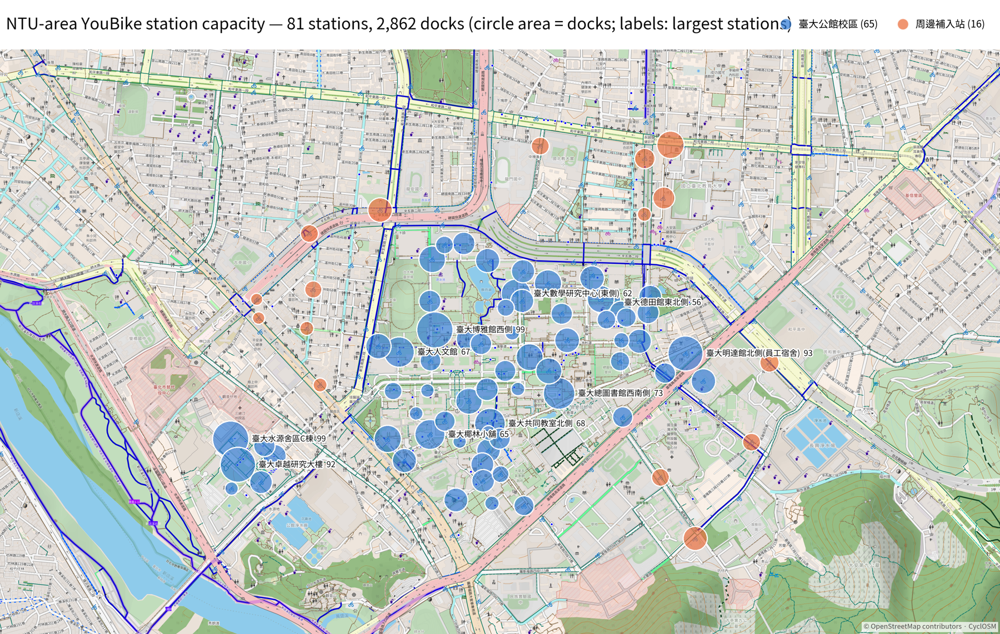

,name,name_en,group,Quantity
0,臺大博雅館西側,NTU Liberal Education Classroom Building(West),臺大公館校區,99
1,臺大水源舍區C棟,NTU Shui-Yuan Dorms C,臺大公館校區,99
2,臺大明達館北側(員工宿舍),NTU Ming - Da Hall (Staff Dormitory),臺大公館校區,93
3,臺大卓越研究大樓,NTU Complex for Research Excellence,臺大公館校區,92
4,臺大總圖書館西南側,NTU Main Library(Southwest),臺大公館校區,73
...,...,...,...,...
76,臺大二號館,NTU Building No.2,臺大公館校區,10
77,臺大小小福西南側,NTU Xiao Xiao Fu Commissary(Southwest),臺大公館校區,10
78,臺大森林館北側,NTU Forestry Building(North),臺大公館校區,10
79,羅斯福路三段245號前,No. 245， Sec. 3， Roosevelt Rd.,周邊補入站,8


In [ ]:
qmax = ntu['Quantity'].max()
GROUP_COLOR = {'臺大公館校區': BLUE, '周邊補入站': ORANGE}
img = draw_circles(ntu, 'Quantity', qmax, lambda r: GROUP_COLOR[r['group']])
img.convert('RGB').save(saved('map1_station_capacity_nolabels.png'))

fig, (ax,) = map_figure(1, title_px=0)
show_map(ax, img, ntu, 'Quantity', n_labels=10)
add_header(fig, f'NTU-area YouBike station capacity — {len(ntu)} stations, {ntu["Quantity"].sum():,} docks '
                f'(circle area = docks; labels: largest stations)',
           [dot(BLUE, f'臺大公館校區 ({(ntu.group == "臺大公館校區").sum()})', .7),
            dot(ORANGE, f'周邊補入站 ({(ntu.group == "周邊補入站").sum()})', .7)])
finish(fig, 'map1_station_capacity.png')
ntu[['name', 'name_en', 'group', 'Quantity']].sort_values('Quantity', ascending=False).reset_index(drop=True)

## 2. 所有腳踏車使用時間分布圖 — Bikes Borrowed and In Use by Hour
- **Borrowed**: average rentals per day that *start* at an NTU station in each hour.
- **In use**: average bikes on the road per day in each hour, for every trip that starts or ends at NTU. A trip counts in every hour from its rent hour to its return hour (the trip data is recorded at hourly resolution).

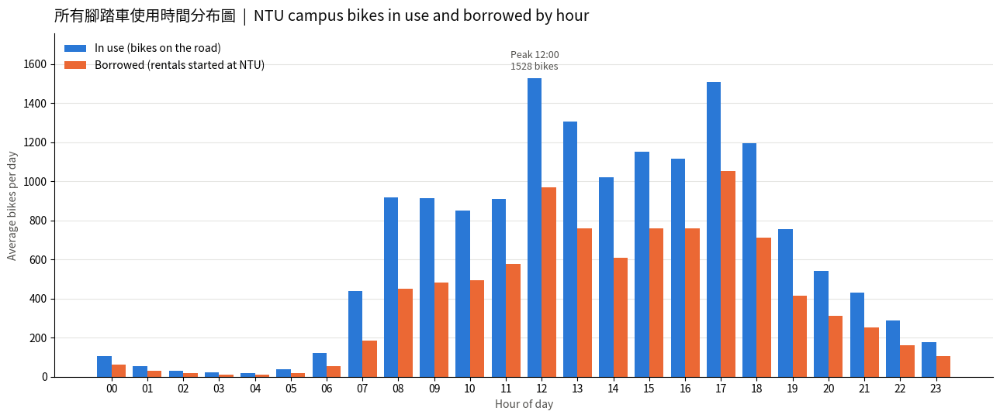

,hour,borrowed_per_day,in_use_per_day
0,0,61.1,107.1
1,1,30.4,54.2
2,2,17.8,32.3
3,3,11.2,21.0
4,4,9.3,17.7
5,5,17.8,37.4
6,6,53.5,120.0
7,7,187.1,439.9
8,8,452.2,917.3
9,9,481.7,914.9


In [ ]:
# Borrowed per hour
borrowed = (np.bincount(trips.loc[trips['rent_at_ntu'], 'rent_hour'], minlength=24) / n_days)

# In use per hour: expand each trip over the hours it spans
start = trips['rent_time'].dt.floor('h')
span = ((trips['return_time'].dt.floor('h') - start) / pd.Timedelta(hours=1)).astype(int) + 1
span_v = span.to_numpy()
offsets = np.arange(span_v.sum()) - np.repeat(np.cumsum(span_v) - span_v, span_v)
hours_in_use = (np.repeat(start.dt.hour.to_numpy(), span_v) + offsets) % 24
in_use = np.bincount(hours_in_use, minlength=24) / n_days

hourly = pd.DataFrame({'hour': range(24), 'borrowed_per_day': borrowed.round(1),
                       'in_use_per_day': in_use.round(1)})

fig, ax = plt.subplots(figsize=(13, 5.5))
x = np.arange(24); w = 0.4
ax.bar(x - w/2, in_use, w, color=BLUE, label='In use (bikes on the road)')
ax.bar(x + w/2, borrowed, w, color=ORANGE, label='Borrowed (rentals started at NTU)')
ax.set_xticks(x, [f'{h:02d}' for h in x])
ax.set_xlabel('Hour of day', color=INK2)
ax.set_ylabel('Average bikes per day', color=INK2)
ax.set_title('所有腳踏車使用時間分布圖  |  NTU campus bikes in use and borrowed by hour',
             loc='left', fontsize=14, color=INK, pad=12)
ax.set_ylim(0, max(in_use.max(), borrowed.max()) * 1.15)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', color='#e5e5e2', linewidth=0.8); ax.set_axisbelow(True)
ax.legend(frameon=False, loc='upper left')
peak = int(np.argmax(in_use))
ax.annotate(f'Peak {peak:02d}:00\n{in_use[peak]:.0f} bikes', (peak - w/2, in_use[peak]),
            xytext=(0, 8), textcoords='offset points', ha='center', fontsize=9, color=INK2)
plt.tight_layout(); plt.savefig(saved('chart2_hourly_usage.png'), dpi=150); plt.show()
hourly

## 3. Average Commute Time Between Two Campus Stations
Trips where **both** the rent and return station are NTU stations, excluding round trips (same station).
Outliers are removed **per station pair** with the IQR rule (keep Q1 − 1.5·IQR to Q3 + 1.5·IQR), which drops trips where the rider made stops along the way.
Only pairs with at least `MIN_TRIPS` trips after cleaning are shown.

In [ ]:
MIN_TRIPS = 20

campus = trips[trips['rent_at_ntu'] & trips['return_at_ntu']
               & (trips['rent_station'] != trips['return_station'])].copy()

pair = campus.groupby(['rent_station', 'return_station'])['duration_s']
q1 = pair.transform(lambda s: s.quantile(0.25))
q3 = pair.transform(lambda s: s.quantile(0.75))
iqr = q3 - q1
clean = campus[(campus['duration_s'] >= q1 - 1.5 * iqr) & (campus['duration_s'] <= q3 + 1.5 * iqr)]
print(f'{len(campus):,} campus-to-campus trips; {len(campus) - len(clean):,} outliers removed '
      f'({(len(campus) - len(clean)) / max(len(campus), 1):.1%})')

def mmss(s):
    s = int(round(s)); return f'{s // 60}:{s % 60:02d}'

commute = (clean.groupby(['rent_station', 'return_station'])['duration_s']
           .agg(trips='size', avg_s='mean', median_s='median').reset_index())
commute = commute[commute['trips'] >= MIN_TRIPS].sort_values('trips', ascending=False)
commute['Avg commute time (min:sec)'] = commute['avg_s'].map(mmss)
commute['Median (min:sec)'] = commute['median_s'].map(mmss)

commute_table = commute.rename(columns={'rent_station': 'Rent station (租借站)',
                                        'return_station': 'Return station (歸還站)',
                                        'trips': 'Trips'})[
    ['Rent station (租借站)', 'Return station (歸還站)', 'Avg commute time (min:sec)',
     'Median (min:sec)', 'Trips']].reset_index(drop=True)
commute_table.to_csv(saved('table3_campus_commute_times.csv'), index=False, encoding='utf-8-sig')
print(f'{len(commute_table):,} station pairs with >= {MIN_TRIPS} trips (full table saved to CSV)')
print('Top 30 most-travelled pairs:')
display(commute_table.head(30).style.hide(axis='index'))

3,460,961 campus-to-campus trips; 417,394 outliers removed (12.1%)
4,850 station pairs with >= 20 trips (full table saved to CSV)
Top 30 most-travelled pairs:


Rent station (租借站),Return station (歸還站),Avg commute time (min:sec),Median (min:sec),Trips
臺大新體育館東南側,臺大第一活動中心西南側,4:49,4:35,11055
臺大椰林小舖,臺大第一活動中心西南側,3:25,3:17,10813
臺大第一活動中心西南側,臺大椰林小舖,3:36,3:29,10782
臺大第一活動中心西南側,臺大新體育館東南側,4:18,4:08,9753
臺大小福樓東側,臺大第一活動中心西南側,2:27,2:15,9725
臺大第一活動中心西南側,臺大小福樓東側,2:13,1:59,9082
臺大社科院西側,臺大小福樓東側,3:24,3:14,8213
臺大小福樓東側,臺大大一女舍北側,3:44,3:37,8040
臺大小福樓東側,臺大社科院西側,3:26,3:17,7552
臺大大一女舍北側,臺大第一活動中心西南側,4:23,4:13,7439


In [ ]:
# Look up any pair (both directions)
def commute_between(a, b):
    return commute_table[((commute_table['Rent station (租借站)'] == a) & (commute_table['Return station (歸還站)'] == b)) |
                         ((commute_table['Rent station (租借站)'] == b) & (commute_table['Return station (歸還站)'] == a))]

# Example: the busiest pair. Replace with any two station names, e.g. commute_between('臺大小福樓東側', '臺大總圖書館西南側')
top = commute_table.iloc[0]
commute_between(top['Rent station (租借站)'], top['Return station (歸還站)'])

,Rent station (租借站),Return station (歸還站),Avg commute time (min:sec),Median (min:sec),Trips
0,臺大新體育館東南側,臺大第一活動中心西南側,4:49,4:35,11055
3,臺大第一活動中心西南側,臺大新體育館東南側,4:18,4:08,9753


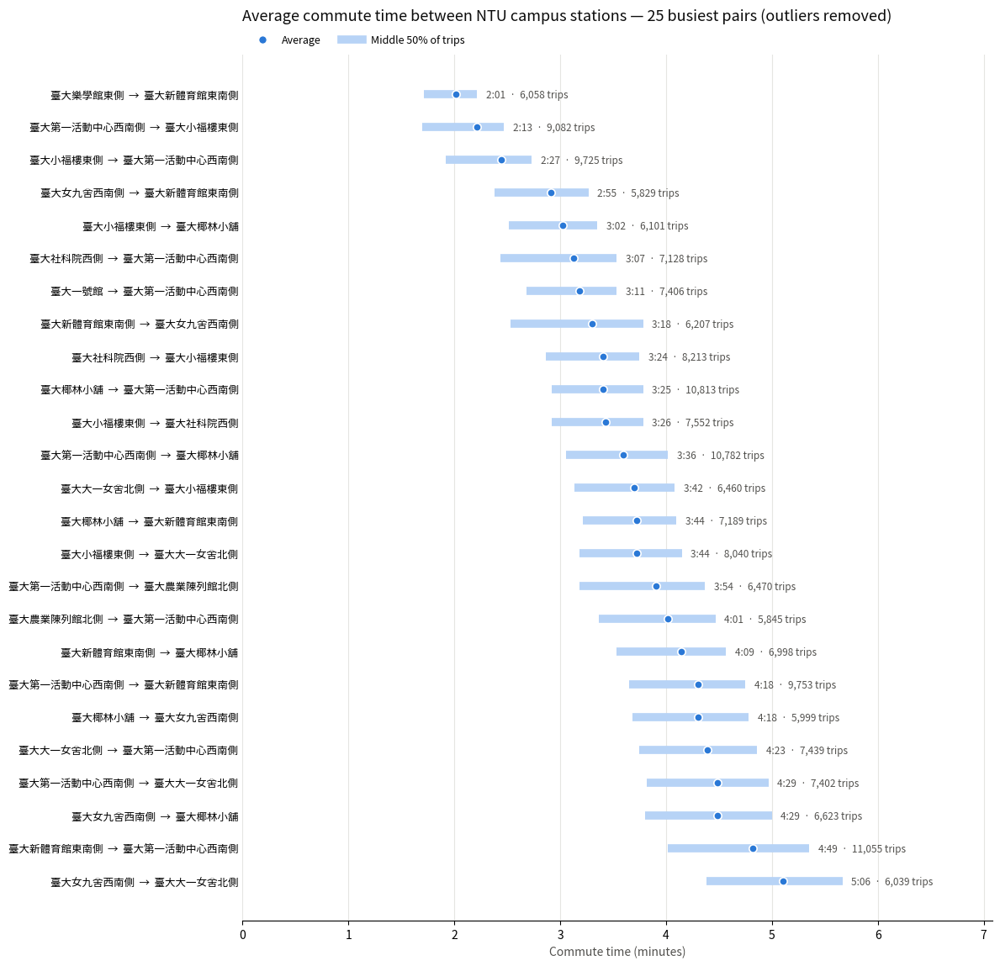

In [ ]:
# Chart: average commute time for the busiest campus station pairs
TOP_N = 25   # number of station pairs to show (the most-travelled ones)

pair_stats = (clean.groupby(['rent_station', 'return_station'])['duration_s']
              .agg(trips='size', avg='mean',
                   q1=lambda s: s.quantile(0.25), q3=lambda s: s.quantile(0.75))
              .reset_index())
pair_stats = (pair_stats[pair_stats['trips'] >= MIN_TRIPS]
              .nlargest(TOP_N, 'trips').sort_values('avg').reset_index(drop=True))
pair_stats[['avg', 'q1', 'q3']] = pair_stats[['avg', 'q1', 'q3']] / 60   # seconds -> minutes
pair_stats['label'] = pair_stats['rent_station'] + '  →  ' + pair_stats['return_station']

fig, ax = plt.subplots(figsize=(12, 0.4 * len(pair_stats) + 1.6))
y = np.arange(len(pair_stats))
ax.hlines(y, pair_stats['q1'], pair_stats['q3'], color='#b7d3f6', linewidth=7, zorder=2)
ax.scatter(pair_stats['avg'], y, s=45, color=BLUE, edgecolor='white', linewidth=1.2, zorder=3)
xmax = pair_stats['q3'].max()
for i, r in pair_stats.iterrows():
    ax.text(r['q3'] + xmax * 0.015, i, f"{mmss(r['avg'] * 60)}  ·  {r['trips']:,} trips",
            va='center', fontsize=8.5, color=INK2)

ax.set_yticks(y, pair_stats['label'], fontsize=9)
ax.invert_yaxis()                                   # fastest commute at the top
ax.set_xlim(0, xmax * 1.25)
ax.set_xlabel('Commute time (minutes)', color=INK2)
ax.set_title(f'Average commute time between NTU campus stations — {len(pair_stats)} busiest pairs '
             f'(outliers removed)', loc='left', fontsize=13, color=INK, pad=30)
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.tick_params(axis='y', length=0)
ax.grid(axis='x', color='#e5e5e2', linewidth=0.8); ax.set_axisbelow(True)
ax.legend(handles=[Line2D([], [], marker='o', ls='', ms=7, mfc=BLUE, mec='white', label='Average'),
                   Line2D([], [], color='#b7d3f6', lw=7, label='Middle 50% of trips')],
          loc='lower left', bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, fontsize=9)
plt.tight_layout(); plt.savefig(saved('chart3_campus_commute_times.png'), dpi=150, bbox_inches='tight'); plt.show()

## 4 & 5. Station Activity and Net Flow at 09:00, 12:00 and 16:00
For each NTU station and hour, averaged over all days in the data:
- **Total activity** = rentals + returns
- **Net flow** = returns − rentals
  - 🟢 **Demand (green)**: more returns than rentals — riders are arriving, so the station needs empty docks.
  - 🔴 **Supply (red)**: more rentals than returns — riders are leaving, so the station supplies bikes.

Circle sizes use one scale across the three hours, so they can be compared directly.

In [ ]:
HOURS = [9, 12, 16]

rent_h = (trips[trips['rent_at_ntu']].groupby(['rent_station', 'rent_hour']).size()
          .rename_axis(['name', 'hour']))
ret_h = (trips[trips['return_at_ntu']].groupby(['return_station', 'return_hour']).size()
         .rename_axis(['name', 'hour']))
flow = pd.concat({'rentals': rent_h, 'returns': ret_h}, axis=1).fillna(0) / n_days
flow['activity'] = flow['rentals'] + flow['returns']
flow['net'] = flow['returns'] - flow['rentals']

# Every study-area station x every hour (stations with no trips get 0)
idx = pd.MultiIndex.from_product([sorted(ntu_names), range(24)], names=['name', 'hour'])
flow = (flow.reindex(idx, fill_value=0).reset_index()
        .merge(ntu[['name', 'name_en', 'group', 'latitude', 'longitude', 'Quantity']], on='name'))
flow_sel = flow[flow['hour'].isin(HOURS)]

def three_panel(images, value_col, titles, suptitle, legend, fname, fmt, n_labels=5):
    """Panels stacked vertically (the maps are wide), one shared circle scale."""
    fig, axes = map_figure(len(images))
    vmax = flow_sel[value_col].abs().max()
    for ax, h, img, t in zip(axes, HOURS, images, titles):
        show_map(ax, img, flow_sel[flow_sel['hour'] == h], value_col, t, n_labels=n_labels, fmt=fmt, vmax=vmax)
    add_header(fig, suptitle, legend)
    finish(fig, fname)

map4_activity_9_12_16.png: 3232 x 6097 px


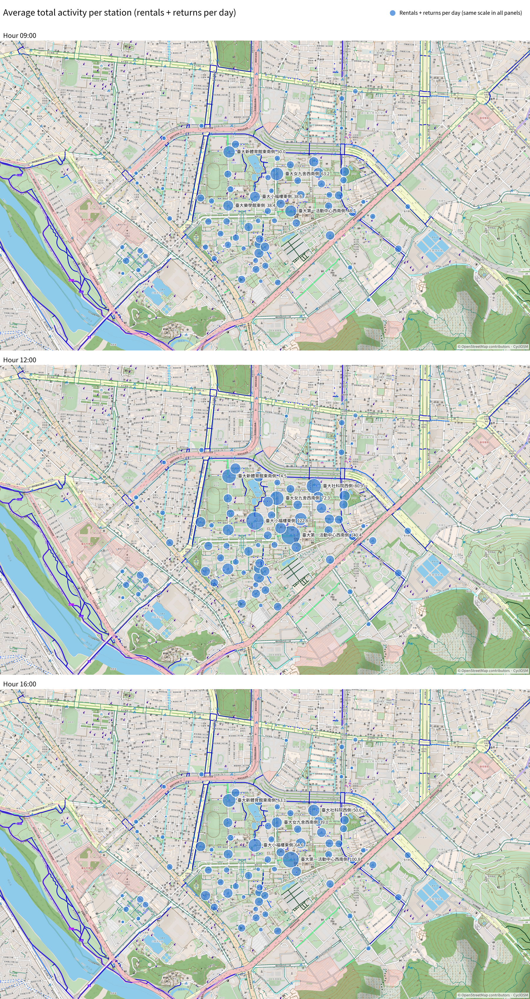

hour,9,12,16
name,,,
臺大女九舍西南側,63.2,72.3,39.0
臺大新體育館東南側,50.0,74.5,63.1
臺大第一活動中心西南側,48.7,140.4,100.8
臺大小福樓東側,38.6,122.8,64.6
臺大樂學館東側,38.4,45.3,30.0
臺大社會系館南側,37.8,42.5,29.2
臺大社科院西側,33.3,80.9,50.6
臺大鹿鳴堂東側,31.5,42.9,25.0
臺大黑森林西側,30.1,40.7,25.2


In [ ]:
# 4. Activity map
amax = flow_sel['activity'].max()
activity_imgs = []
for h in HOURS:
    img = draw_circles(flow_sel[flow_sel['hour'] == h], 'activity', amax, lambda r: BLUE)
    img.convert('RGB').save(saved(f'map4_activity_hour{h:02d}.png'))
    activity_imgs.append(img)

three_panel(activity_imgs, 'activity', [f'Hour {h:02d}:00' for h in HOURS],
            'Average total activity per station (rentals + returns per day)',
            [dot(BLUE, 'Rentals + returns per day (same scale in all panels)', .7)],
            'map4_activity_9_12_16.png', '{:.1f}')
(flow_sel.pivot_table(index='name', columns='hour', values='activity').round(1)
 .sort_values(HOURS[0], ascending=False).head(10))

map5_netflow_9_12_16.png: 3232 x 6097 px


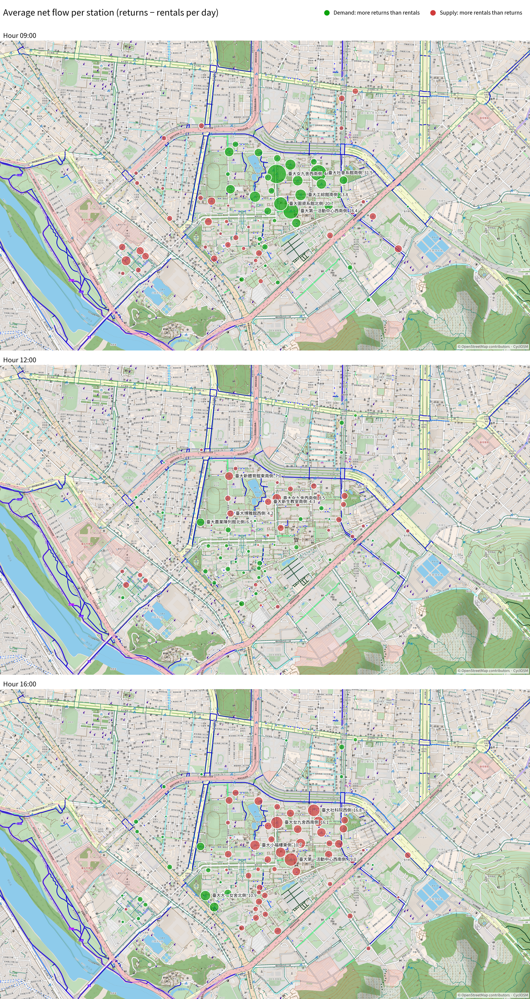

hour,9,12,16
name,,,
臺大女九舍西南側,44.5,-8.5,-16.1
臺大社會系館南側,31.5,-3.3,-10.4
臺大第一活動中心西南側,28.4,0.0,-19.0
臺大圖資系館北側,20.7,-3.8,-10.6
臺大工綜館南側,13.8,1.3,-9.8
...,...,...,...
臺大男七舍前,-5.6,1.1,-0.3
臺大一號館,-5.7,1.1,1.7
臺大水源舍區B棟,-6.0,-1.8,2.1


In [ ]:
# 5. Net flow map
nmax = flow_sel['net'].abs().max()
net_imgs = []
for h in HOURS:
    img = draw_circles(flow_sel[flow_sel['hour'] == h], 'net', nmax,
                       lambda r: GREEN if r['net'] > 0 else RED, alpha=0.7)
    img.convert('RGB').save(saved(f'map5_netflow_hour{h:02d}.png'))
    net_imgs.append(img)

three_panel(net_imgs, 'net', [f'Hour {h:02d}:00' for h in HOURS],
            'Average net flow per station (returns − rentals per day)',
            [dot(GREEN, 'Demand: more returns than rentals'), dot(RED, 'Supply: more rentals than returns')],
            'map5_netflow_9_12_16.png', '{:.1f}')
(flow_sel.pivot_table(index='name', columns='hour', values='net').round(1)
 .sort_values(HOURS[0], ascending=False))

## 6. Bike Route Heatmap — Hours 09, 11 and 16
The trip records only give the rent and return station, not the GPS track, so each trip is assigned to its **shortest bike route on the OpenStreetMap network** (OSMnx, `network_type='bike'`; both directions allowed because riders also use sidewalks and campus paths). Each road segment then gets the **average number of trips per day** passing along it, for trips **rented in that hour** that start or end at a study-area station.

- Color (light → dark orange) and line width use **one log scale across the three hours**, so the panels compare directly.
- Round trips (same rent and return station) have no route and are left out. Trips whose other end is beyond the map edge + `GRAPH_PAD` are left out too; the coverage table shows the share routed.
- These are estimated routes: real riders may take quieter streets than the shortest path.


In [ ]:
# 6a. Route every trip on the OSM bike network
import osmnx as ox
import networkx as nx

HEAT_HOURS = [9, 11, 16]
GRAPH_PAD = 0.012      # road network beyond the map edge (deg), so trips heading off the map are still routed

# Coordinates for every station: Taipei API (stationInfo) + New Taipei API (trips across the river to 永和/中和)
coords = stations_all[['name', 'latitude', 'longitude']].copy()
try:
    pages = []
    for page in range(10):
        p = pd.read_json('https://data.ntpc.gov.tw/api/datasets/010e5b15-3823-4b20-b401-b1cf000550c5/json'
                         f'?page={page}&size=1000')
        if p.empty:
            break
        pages.append(p)
    ntpc = pd.concat(pages).rename(columns={'lat': 'latitude', 'lng': 'longitude'})
    ntpc['name'] = ntpc['sna'].map(norm_name)
    coords = pd.concat([coords, ntpc[['name', 'latitude', 'longitude']]])
    print(f'{len(ntpc)} New Taipei stations added')
except Exception as e:
    print('New Taipei station list not loaded (trips to New Taipei are skipped):', e)
coords[['latitude', 'longitude']] = coords[['latitude', 'longitude']].astype(float)
STATION_COORDS = coords.drop_duplicates('name').set_index('name')

# Average trips per day for every station pair, by rent hour (round trips have no route)
od = trips[trips['rent_hour'].isin(HEAT_HOURS) & (trips['rent_station'] != trips['return_station'])]
od = (od.groupby(['rent_hour', 'rent_station', 'return_station']).size() / n_days).rename('per_day').reset_index()
od = (od.join(STATION_COORDS.add_prefix('o_'), on='rent_station')
        .join(STATION_COORDS.add_prefix('d_'), on='return_station'))

GW, GS, GE, GN = LON_MIN - GRAPH_PAD, LAT_MIN - GRAPH_PAD, LON_MAX + GRAPH_PAD, LAT_MAX + GRAPH_PAD
has_xy = od[['o_latitude', 'd_latitude']].notna().all(axis=1)
inside = (has_xy & od['o_longitude'].between(GW, GE) & od['d_longitude'].between(GW, GE)
          & od['o_latitude'].between(GS, GN) & od['d_latitude'].between(GS, GN))
od_r = od[inside].copy()
coverage = pd.DataFrame({'trips/day (non-round)': od.groupby('rent_hour')['per_day'].sum(),
                         'routed share': od_r.groupby('rent_hour')['per_day'].sum()
                                         / od.groupby('rent_hour')['per_day'].sum(),
                         'no station coords': od[~has_xy].groupby('rent_hour')['per_day'].sum()
                                              / od.groupby('rent_hour')['per_day'].sum()}).fillna(0)
display(coverage.style.format({'trips/day (non-round)': '{:,.0f}', 'routed share': '{:.1%}',
                               'no station coords': '{:.1%}'}))

# Road network for cycling. Both directions allowed: riders also use sidewalks and campus paths.
print('Downloading the OSM bike network ...')
try:
    G = ox.graph_from_bbox(bbox=(GW, GS, GE, GN), network_type='bike')     # OSMnx >= 2.0
except TypeError:
    G = ox.graph_from_bbox(GN, GS, GE, GW, network_type='bike')           # OSMnx 1.x
try:
    Gu = ox.convert.to_undirected(G)
except AttributeError:
    Gu = ox.get_undirected(G)
print(f'{Gu.number_of_nodes():,} nodes, {Gu.number_of_edges():,} edges')

# Snap stations to the network, then one Dijkstra per study-area station (every trip has one end there)
names = pd.unique(pd.concat([od_r['rent_station'], od_r['return_station']]))
xy = STATION_COORDS.loc[names]
node_of = dict(zip(names, ox.distance.nearest_nodes(Gu, X=xy['longitude'].values, Y=xy['latitude'].values)))
o_node, d_node = od_r['rent_station'].map(node_of), od_r['return_station'].map(node_of)
o_ntu = od_r['rent_station'].isin(ntu_names)
od_r['src'] = np.where(o_ntu, o_node, d_node)
od_r['dst'] = np.where(o_ntu, d_node, o_node)

t0 = time.time()
paths = {}
for src, grp in od_r.groupby('src'):
    _, p = nx.single_source_dijkstra(Gu, src, weight='length')
    for dst in set(grp['dst']):
        if dst in p:
            paths[(src, dst)] = p[dst]
print(f'{len(paths):,} routes computed in {time.time() - t0:.0f}s')

# Trips per day on every road segment (both directions combined)
seg_flow = {h: {} for h in HEAT_HOURS}
for h, src, dst, v in od_r[['rent_hour', 'src', 'dst', 'per_day']].itertuples(index=False):
    p = paths.get((src, dst))
    if not p or len(p) < 2:
        continue
    f = seg_flow[h]
    for u, w in zip(p[:-1], p[1:]):
        key = (u, w) if u < w else (w, u)
        f[key] = f.get(key, 0.0) + v

_geom = {}
def edge_data(key):
    return min(Gu.get_edge_data(*key).values(), key=lambda d: d.get('length', 0))

def edge_px(key):
    """Pixel polyline of a road segment (uses the OSM geometry when the segment is curved)."""
    if key not in _geom:
        d = edge_data(key)
        if 'geometry' in d:
            lon, lat = np.asarray(d['geometry'].xy)
        else:
            u, v = key
            lon = [Gu.nodes[u]['x'], Gu.nodes[v]['x']]; lat = [Gu.nodes[u]['y'], Gu.nodes[v]['y']]
        _geom[key] = np.column_stack(to_px(lon, lat))
    return _geom[key]

def street_name(key):
    n = edge_data(key).get('name', '')
    return '/'.join(n) if isinstance(n, list) else (n if isinstance(n, str) else '')

1622 New Taipei stations added


,trips/day (non-round),routed share,no station coords
rent_hour,,,
9,767,97.2%,0.5%
11,765,98.0%,0.3%
16,945,97.0%,0.3%


10,012 nodes, 14,104 edges
19,206 routes computed in 12s


map6_route_heat_hour09.png: 3232 x 2399 px


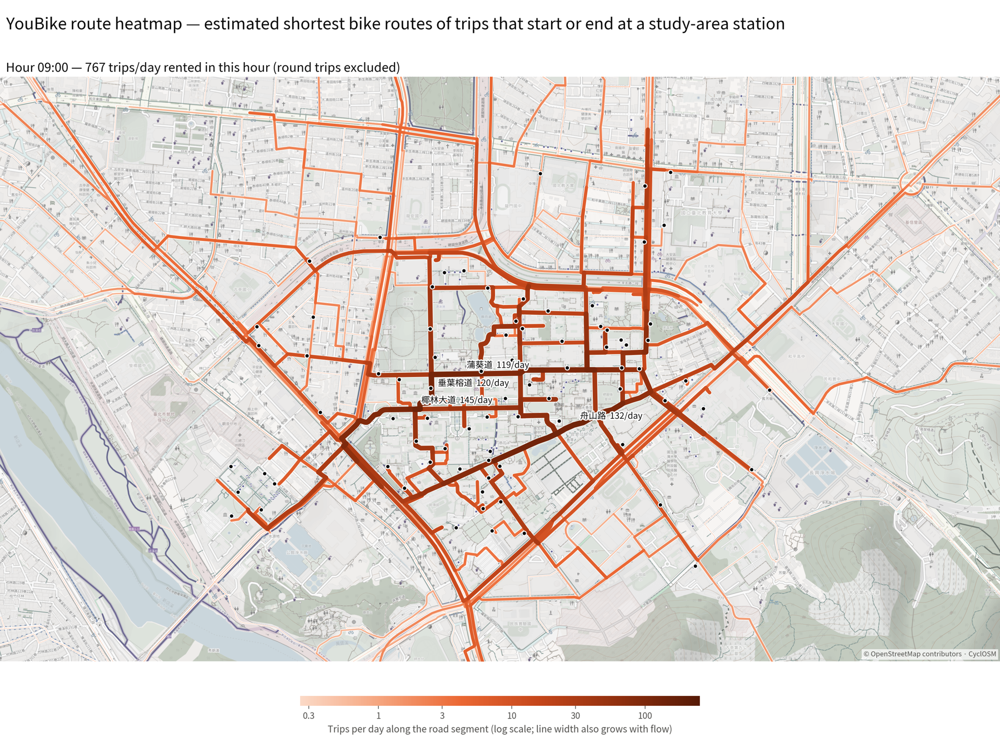

map6_route_heat_hour11.png: 3232 x 2399 px


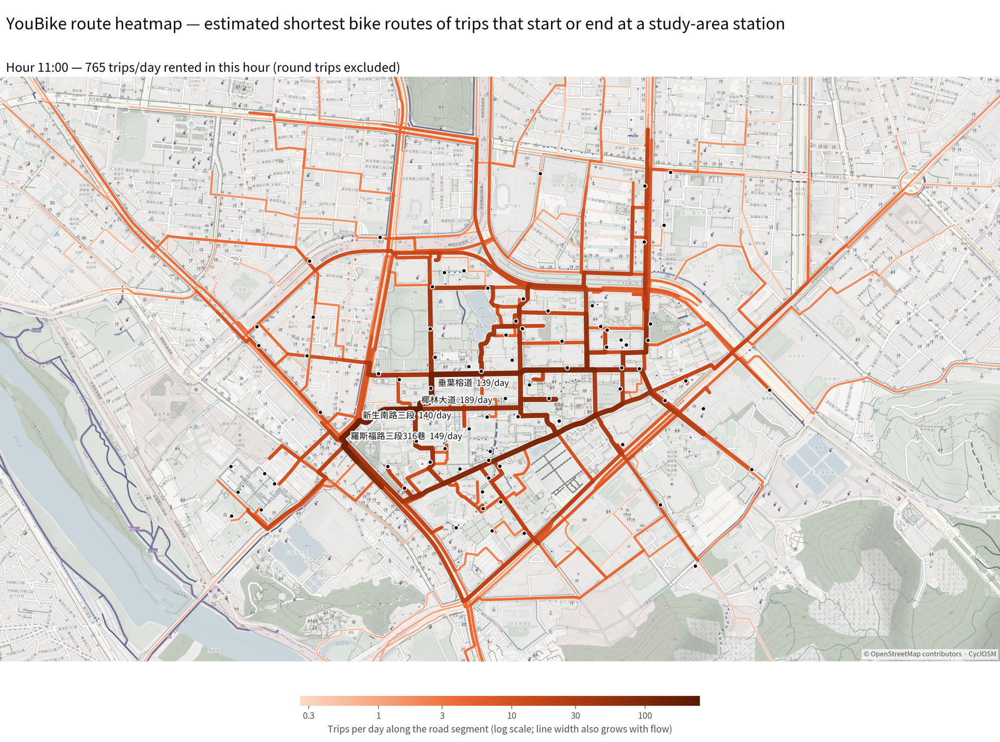

map6_route_heat_hour16.png: 3232 x 2399 px


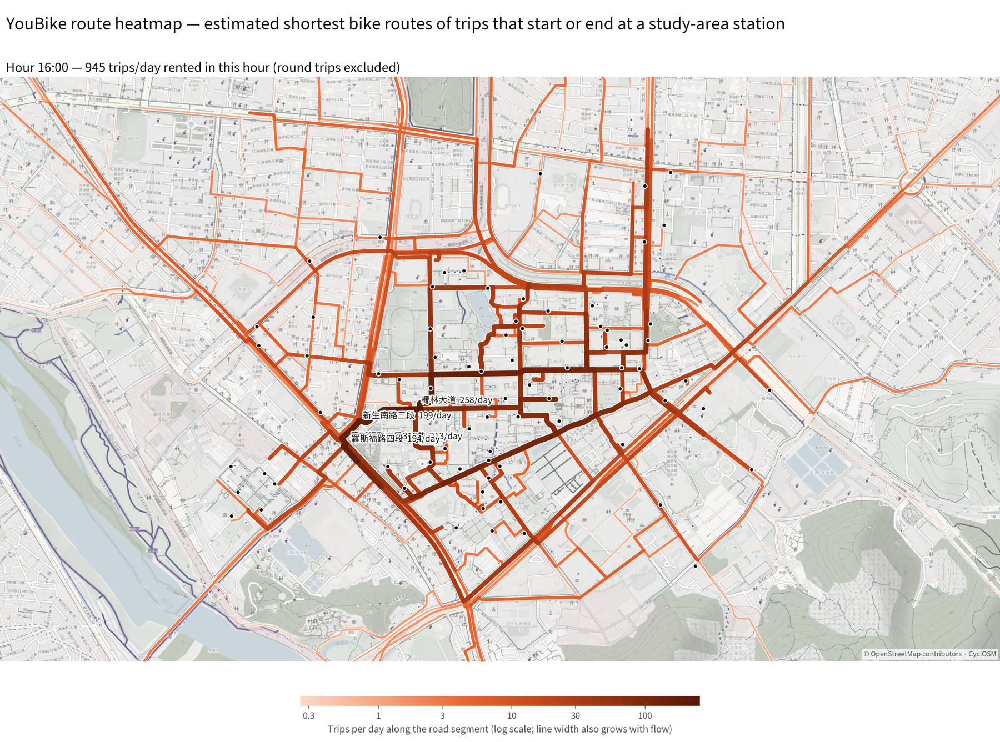

map6_route_heat_9_11_16.png: 3232 x 6357 px


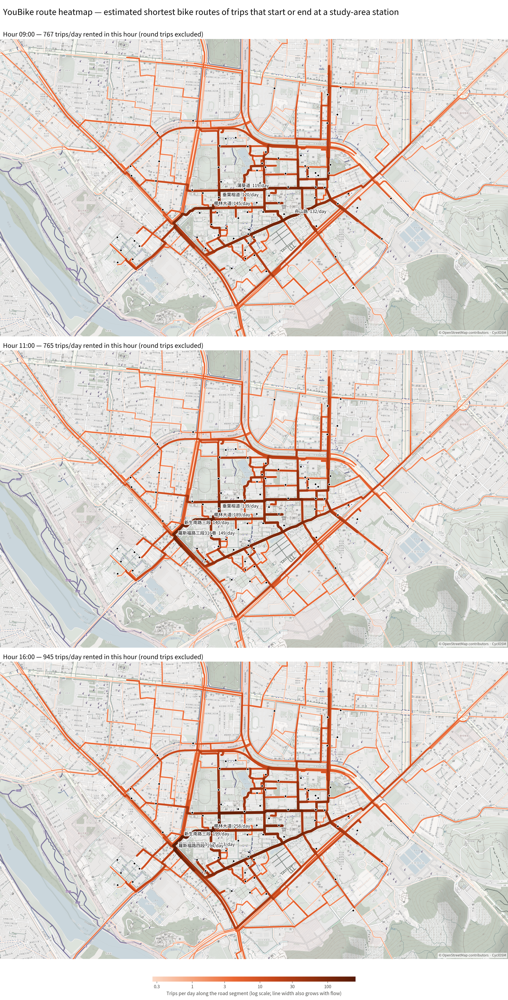

In [ ]:
# 6b. Route heatmap: one shared color/width scale for the three hours
HEAT_CMAP = LinearSegmentedColormap.from_list(
    'heat_orange', ['#fbd9c6', '#f5a47d', '#eb6834', '#c4461a', '#8f2f0e', '#561a06'])
all_vals = np.concatenate([np.fromiter(f.values(), float) for f in seg_flow.values() if f])
HEAT_VMAX = all_vals.max()
HEAT_VMIN = max(np.percentile(all_vals, 5), HEAT_VMAX / 1000)
heat_norm = LogNorm(vmin=HEAT_VMIN, vmax=HEAT_VMAX, clip=True)

# Faded, desaturated basemap so the heat layer stands out
_g = ImageEnhance.Color(BASEMAP.convert('RGB')).enhance(0.3)
HEAT_BASE = Image.blend(_g, Image.new('RGB', _g.size, 'white'), 0.35)

def lw_px(v):                        # line width grows with flow (log scale), in image pixels
    return (1.0 + 9.0 * np.asarray(heat_norm(v))) * S

def heat_panel(ax, h, n_labels=4):
    f = seg_flow[h]
    keys = sorted(f, key=f.get)                      # busiest drawn last (on top)
    segs = [edge_px(k) for k in keys]
    vals = np.array([f[k] for k in keys])
    ax.imshow(HEAT_BASE); ax.set_axis_off()
    lws = px2pt(lw_px(vals))
    ax.add_collection(LineCollection(segs, colors='white', linewidths=lws + px2pt(2 * S),
                                     capstyle='round', joinstyle='round', alpha=0.9))   # 2-px surface ring
    ax.add_collection(LineCollection(segs, cmap=HEAT_CMAP, norm=heat_norm, array=vals, linewidths=lws,
                                     capstyle='round', joinstyle='round'))
    ax.set_xlim(0, MAP_W); ax.set_ylim(MAP_H, 0)
    sx, sy = to_px(ntu['longitude'].values, ntu['latitude'].values)
    ax.scatter(sx, sy, s=float(px2pt(7 * S)) ** 2, c=INK, edgecolors='white',
               linewidths=float(px2pt(1.5 * S)), zorder=5)
    # Direct labels: the busiest segment of the top streets
    best = {}
    for k in reversed(keys):
        nm = street_name(k)
        if nm and nm not in best:
            best[nm] = k
        if len(best) >= n_labels:
            break
    for nm, k in best.items():
        xy = edge_px(k); x, y = xy[len(xy) // 2]
        if 0 <= x <= MAP_W and 0 <= y <= MAP_H:
            ax.annotate(f'{nm}  {f[k]:.1f}/day' if f[k] < 10 else f'{nm}  {f[k]:.0f}/day', (x, y), xytext=(float(px2pt(10 * S)), float(px2pt(10 * S))),
                        textcoords='offset points', fontsize=float(px2pt(14 * S)), color=INK,
                        path_effects=[pe.withStroke(linewidth=float(px2pt(4 * S)), foreground='white')], zorder=6)
    total = od.loc[od['rent_hour'] == h, 'per_day'].sum()
    ax.set_title(f'Hour {h:02d}:00 — {total:,.0f} trips/day rented in this hour (round trips excluded)',
                 loc='left', x=0.006, fontsize=float(px2pt(20 * S)), color=INK, pad=float(px2pt(8 * S)))
    attribution(ax)

def heat_colorbar(fig, footer_px):
    H = fig.get_figheight() * MAP_DPI
    cax = fig.add_axes([0.30, (footer_px * 0.45 * S) / H, 0.40, (16 * S) / H])
    cb = fig.colorbar(ScalarMappable(norm=heat_norm, cmap=HEAT_CMAP), cax=cax, orientation='horizontal')
    ticks = [t for t in [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100, 300, 1000] if HEAT_VMIN <= t <= HEAT_VMAX]
    cb.set_ticks(ticks); cb.set_ticklabels([f'{t:g}' for t in ticks]); cb.minorticks_off()
    cb.ax.tick_params(labelsize=float(px2pt(14 * S)), colors=INK2)
    cb.outline.set_visible(False)
    cb.set_label('Trips per day along the road segment (log scale; line width also grows with flow)',
                 fontsize=float(px2pt(15 * S)), color=INK2)

HEAD = 'YouBike route heatmap — estimated shortest bike routes of trips that start or end at a study-area station'
FOOT = 130
for h in HEAT_HOURS:                                # one full-size image per hour
    fig, (ax,) = map_figure(1, footer_px=FOOT)
    heat_panel(ax, h); add_header(fig, HEAD); heat_colorbar(fig, FOOT)
    finish(fig, f'map6_route_heat_hour{h:02d}.png')

fig, axes = map_figure(len(HEAT_HOURS), footer_px=FOOT)  # combined figure, same scale
for ax, h in zip(axes, HEAT_HOURS):
    heat_panel(ax, h)
add_header(fig, HEAD); heat_colorbar(fig, FOOT)
finish(fig, 'map6_route_heat_9_11_16.png')

In [ ]:
# Busiest streets per hour: peak trips/day on any segment of that street
rows = []
for h in HEAT_HOURS:
    for k, v in seg_flow[h].items():
        rows.append((h, street_name(k) or '(unnamed path)', v, edge_data(k).get('length', np.nan)))
seg_df = pd.DataFrame(rows, columns=['hour', 'street', 'trips_per_day', 'segment_m'])
seg_df.to_csv(saved('table6_route_segments.csv'), index=False, encoding='utf-8-sig')
(seg_df.groupby(['hour', 'street'])['trips_per_day'].max().round(1)
 .unstack('hour').sort_values(HEAT_HOURS[0], ascending=False).head(15))

hour,9,11,16
street,,,
椰林大道,145.3,189.2,257.7
舟山路,132.1,98.0,128.1
垂葉榕道,119.6,139.4,183.3
蒲葵道,118.7,137.2,173.3
水杉道,117.2,109.5,137.1
(unnamed path),110.9,138.3,187.0
羅斯福路三段316巷,96.7,148.8,213.5
新生南路三段,89.1,139.8,198.7
楓香道,87.3,82.4,95.8


## 7. Upload the outputs to Google Drive (open online)
Uploads every saved PNG / CSV and `可能缺漏站點清單.csv` to the Drive folder `youbike_NTU_outputs` (files are overwritten on re-run, so the links stay the same) and prints a table of links that open the full-size images in the browser. The files are private to your Google account until you share the folder.


In [ ]:
# Upload every saved figure / table (+ the station list) to Google Drive and print links that open online
DRIVE_FOLDER = 'youbike_NTU_outputs'

from google.colab import auth
from googleapiclient.discovery import build
from googleapiclient.http import MediaFileUpload

auth.authenticate_user()
gdrive = build('drive', 'v3')
q = f"name='{DRIVE_FOLDER}' and mimeType='application/vnd.google-apps.folder' and trashed=false"
found = gdrive.files().list(q=q, fields='files(id, webViewLink)').execute()['files']
folder = found[0] if found else gdrive.files().create(
    body={'name': DRIVE_FOLDER, 'mimeType': 'application/vnd.google-apps.folder'},
    fields='id, webViewLink').execute()

rows = []
for path in OUT_FILES + [EXTRA_CSV]:
    if not os.path.exists(path):
        continue
    name = os.path.basename(path)
    mime = 'image/png' if name.endswith('.png') else 'text/csv'
    media = MediaFileUpload(path, mimetype=mime, resumable=True)
    old = gdrive.files().list(q=f"name='{name}' and '{folder['id']}' in parents and trashed=false",
                              fields='files(id)').execute()['files']
    if old:      # overwrite, so the links stay the same when you re-run
        f = gdrive.files().update(fileId=old[0]['id'], media_body=media, fields='id, webViewLink').execute()
    else:
        f = gdrive.files().create(body={'name': name, 'parents': [folder['id']]}, media_body=media,
                                  fields='id, webViewLink').execute()
    size = Image.open(path).size if name.endswith('.png') else None
    rows.append(f"| {name} | {f'{size[0]} x {size[1]} px' if size else 'CSV'} | [open]({f['webViewLink']}) |")

display(Markdown(f"**Folder:** [{DRIVE_FOLDER}]({folder['webViewLink']})\n\n| File | Size | Link |\n|---|---|---|\n"
                 + '\n'.join(rows)))

**Folder:** [youbike_NTU_outputs](https://drive.google.com/drive/folders/1m5Z_LkpXrGnf_A4Xa0BP4gymrnMILIH7)

| File | Size | Link |
|---|---|---|
| map1_station_capacity_nolabels.png | 3232 x 1891 px | [open](https://drive.google.com/file/d/1meBLLHOoa42-ykktDt6xsjxzmXA8aPhD/view?usp=drivesdk) |
| map1_station_capacity.png | 3232 x 2051 px | [open](https://drive.google.com/file/d/1OVYwMywjzBQD7kzEoSKTo7osL1rKpkOS/view?usp=drivesdk) |
| chart2_hourly_usage.png | 1950 x 825 px | [open](https://drive.google.com/file/d/1mpRFwp-T85QhlL00B2oCQlKo_qkOUHNu/view?usp=drivesdk) |
| table3_campus_commute_times.csv | CSV | [open](https://drive.google.com/file/d/1VQerUsC9gTvpefviSCmpCDW0vkDGXyRd/view?usp=drivesdk) |
| chart3_campus_commute_times.png | 1785 x 1726 px | [open](https://drive.google.com/file/d/1F8zqFGgnkz6LNurxGKaPm4NYWRe8yNyJ/view?usp=drivesdk) |
| map4_activity_hour09.png | 3232 x 1891 px | [open](https://drive.google.com/file/d/12wqkTFl5h0FtwG90geeZdiasg6MW_Jbz/view?usp=drivesdk) |
| map4_activity_hour12.png | 3232 x 1891 px | [open](https://drive.google.com/file/d/1BdD-AeR2tpH4wHOLFop_u4qfKfujkzSS/view?usp=drivesdk) |
| map4_activity_hour16.png | 3232 x 1891 px | [open](https://drive.google.com/file/d/1yQAj_WIvdjxYNU-9aw0O4LVSo-TORgfX/view?usp=drivesdk) |
| map4_activity_9_12_16.png | 3232 x 6097 px | [open](https://drive.google.com/file/d/1-A0KsBoMj4K81x42hkBkiGNZZh_vx5Uy/view?usp=drivesdk) |
| map5_netflow_hour09.png | 3232 x 1891 px | [open](https://drive.google.com/file/d/12ozsF9fSde1SfMD-e-LusCrMCLksP8dw/view?usp=drivesdk) |
| map5_netflow_hour12.png | 3232 x 1891 px | [open](https://drive.google.com/file/d/1qc426DpUJcpHQOtmxtl2JtUBfGWjIF3Q/view?usp=drivesdk) |
| map5_netflow_hour16.png | 3232 x 1891 px | [open](https://drive.google.com/file/d/1DdPAvqrBlrvuf62HtbA5LRRYYYV_6Vep/view?usp=drivesdk) |
| map5_netflow_9_12_16.png | 3232 x 6097 px | [open](https://drive.google.com/file/d/1NJlOLu0ja37tDuB6BVnFS8kIRobpPQfk/view?usp=drivesdk) |
| map6_route_heat_hour09.png | 3232 x 2399 px | [open](https://drive.google.com/file/d/1FlAa2gFUM0vjkrCoXzQ3ep3A8e_3BZmT/view?usp=drivesdk) |
| map6_route_heat_hour11.png | 3232 x 2399 px | [open](https://drive.google.com/file/d/1sD3mlfAQF_wXLlKDsT1fQioPZSj2F5I9/view?usp=drivesdk) |
| map6_route_heat_hour16.png | 3232 x 2399 px | [open](https://drive.google.com/file/d/1_W_TjFT7MQ3josNX-DokEaiPHKlgbIKe/view?usp=drivesdk) |
| map6_route_heat_9_11_16.png | 3232 x 6357 px | [open](https://drive.google.com/file/d/1WAoDHDNd1wpLeoLFuOJ493HztL2Sa5jJ/view?usp=drivesdk) |
| table6_route_segments.csv | CSV | [open](https://drive.google.com/file/d/1RXwjYz0Rveun7RrFqznPWojucKsDbnA1/view?usp=drivesdk) |
| 可能缺漏站點清單.csv | CSV | [open](https://drive.google.com/file/d/1wLVNKWMQRXcj00h-4SIZTNoB5xKl7an0/view?usp=drivesdk) |